In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import pyplot as plt
import seaborn as sns
import plotly_express as px
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = sns.load_dataset('titanic')

In [3]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [4]:
 #1.How many passengers are there in the dataset? How many survived vs did not survive?
total_Passenger = len(df)
print("Total_Passenger :" ,total_Passenger)


Total_Passenger : 891


In [9]:
df.shape

(891, 15)

In [10]:
x = df.survived.value_counts()
x

survived
0    549
1    342
Name: count, dtype: int64

In [11]:
print("survived.  :",x[1])
print("not survived.  :",x[0])

survived.  : 342
not survived.  : 549


In [12]:
total = len(df)
survived = df['survived'].value_counts()[1]
not_survived = df['survived'].value_counts()[0]

print(f"--- Titanic Data Summary ---")
print(f"Total Passengers: {total}")
print(f"Survived:         {survived}")
print(f"Did Not Survive:  {not_survived}")

--- Titanic Data Summary ---
Total Passengers: 891
Survived:         342
Did Not Survive:  549


In [13]:
#2. What percentage of data is missing in each column?
x = df.isna().mean()*100

In [14]:
x[x>0]

age            19.865320
embarked        0.224467
deck           77.216611
embark_town     0.224467
dtype: float64

In [15]:
for i in x[x>0].index:
    print(f"{i} : {round(x[i],2)}%")

age : 19.87%
embarked : 0.22%
deck : 77.22%
embark_town : 0.22%


<Axes: xlabel='age', ylabel='Density'>

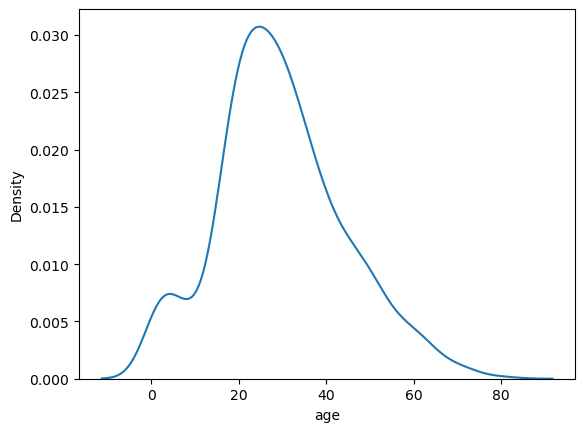

In [16]:
#3. How does the age distribution look? Are there any outliers?
sns.kdeplot(x=df['age'])

<Axes: xlabel='age'>

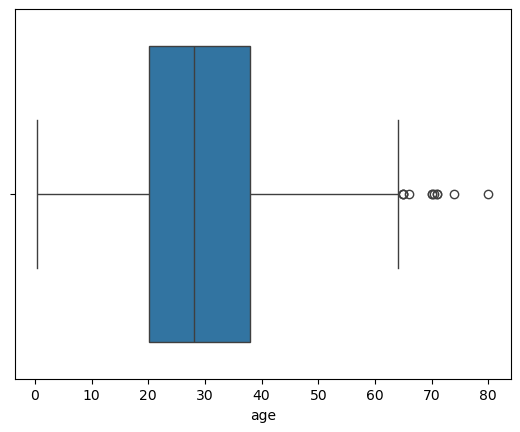

In [17]:
sns.boxplot(x=df['age'])

<Axes: xlabel='sex', ylabel='count'>

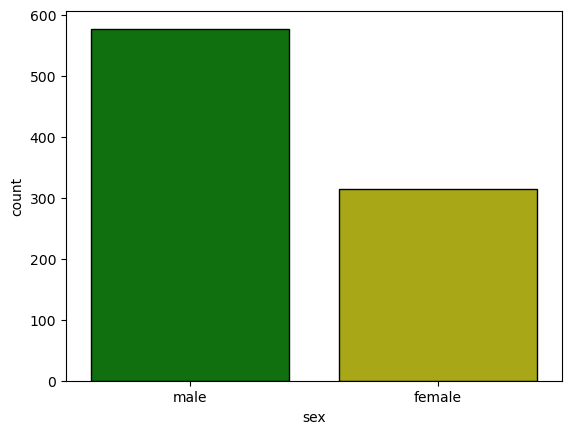

In [18]:
 #4. What is the gender distribution of passengers?
sns.countplot(x=df['sex'],palette=['g','y'],edgecolor='k')

In [20]:
#5. How many passenger belong to each passenger class?
Class = df['pclass'].value_counts().reset_index()

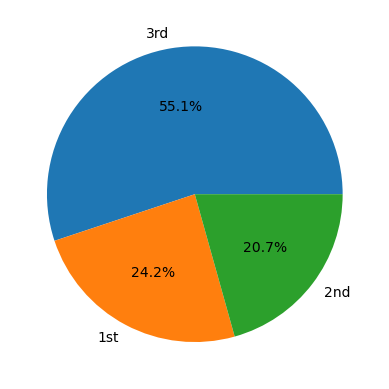

In [23]:
plt.pie(x=Class['count'],labels=['3rd','1st','2nd'],autopct="%1.1f%%")
plt.show()

<Axes: xlabel='age', ylabel='Count'>

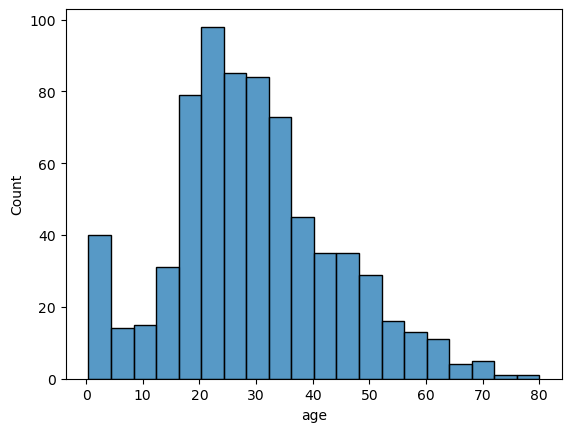

In [43]:
#6. What is the distribution of passenger ages?
sns.histplot(x=df['age'])

<Axes: xlabel='fare', ylabel='Count'>

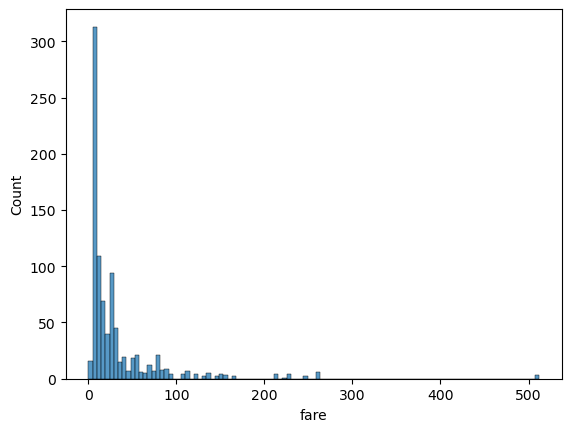

In [25]:
#7. What is the fare distribution, and is it skewed?
sns.histplot(x=df['fare'])

<Axes: xlabel='fare', ylabel='Density'>

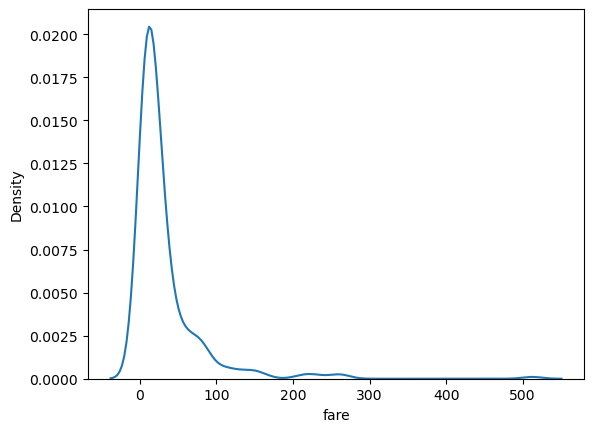

In [26]:
sns.kdeplot(x=df['fare'])

In [27]:
df['fare'].skew()

np.float64(4.787316519674893)

In [31]:
# 8. Which embarkation port has the highest number of passengers?
embark = df['embark_town'].value_counts().reset_index()
embark

,embark_town,count
0,Southampton,644
1,Cherbourg,168
2,Queenstown,77


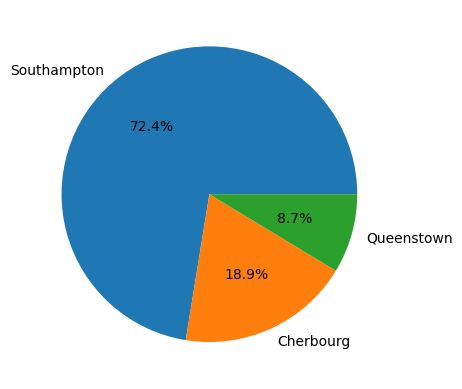

In [49]:
plt.pie(x=embark['count'],labels=embark['embark_town'],autopct="%1.1f%%")
plt.show()

In [51]:
#9. What proportion of passengers were traveling alone vs with family?
A=df['alone'].value_counts().reset_index()
A

,alone,count
0,True,537
1,False,354


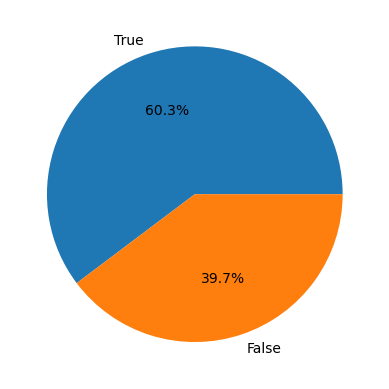

In [54]:
plt.pie(x=A['count'],labels=A['alone'],autopct="%1.1f%%")
plt.show()

In [55]:
#10. How many children (age < 12) were onboard?
df[df['age']<12]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
7,0,3,male,2.00,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
10,1,3,female,4.00,1,1,16.7000,S,Third,child,False,G,Southampton,yes,False
16,0,3,male,2.00,4,1,29.1250,Q,Third,child,False,NaN,Queenstown,no,False
24,0,3,female,8.00,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
43,1,2,female,3.00,1,2,41.5792,C,Second,child,False,NaN,Cherbourg,yes,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
827,1,2,male,1.00,0,2,37.0042,C,Second,child,False,NaN,Cherbourg,yes,False
831,1,2,male,0.83,1,1,18.7500,S,Second,child,False,NaN,Southampton,yes,False
850,0,3,male,4.00,4,2,31.2750,S,Third,child,False,NaN,Southampton,no,False
852,0,3,female,9.00,1,1,15.2458,C,Third,child,False,NaN,Cherbourg,no,False


<Axes: xlabel='survived', ylabel='count'>

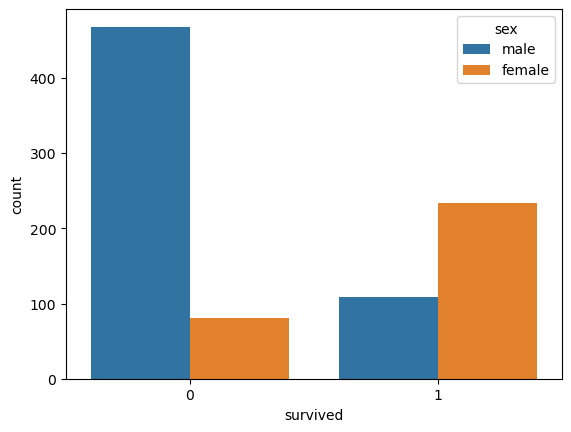

In [56]:
# 11. How does survival rate differ by gender?
sns.countplot(x=df['survived'],hue=df['sex'])

<Axes: xlabel='pclass', ylabel='count'>

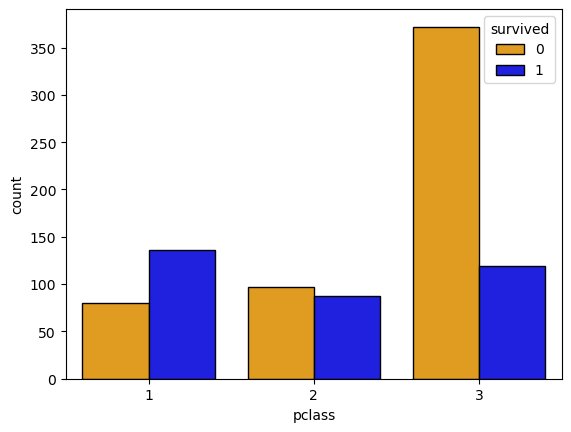

In [57]:
# 12. What is the relationship between passenger class and survival?
sns.countplot(x=df['pclass'],hue=df['survived'],palette=['orange','b'],edgecolor="k")

<Axes: xlabel='survived', ylabel='age'>

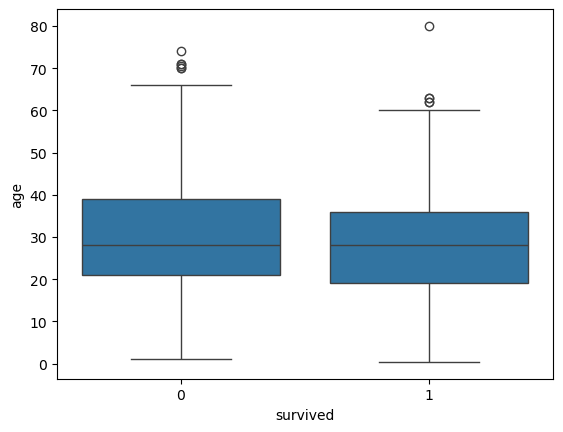

In [58]:
# 13. Does age affect survival probability?
sns.boxplot(y=df['age'],x=df['survived'])

<Axes: xlabel='age', ylabel='Density'>

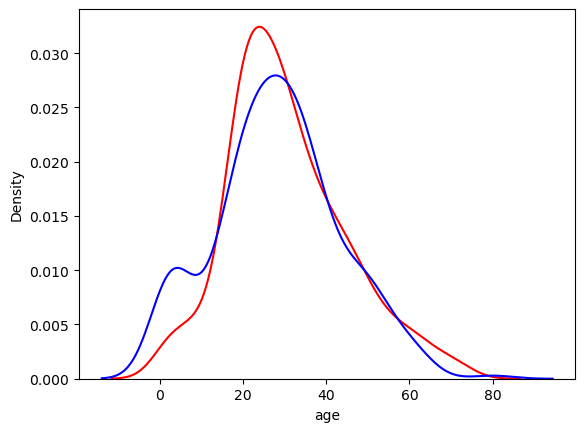

In [59]:
A= df['age'][df['survived']==0]
B= df['age'][df['survived']==1]

sns.distplot(A,hist=False,color ='red')
sns.distplot(B,hist=False,color="b")


<Axes: xlabel='age', ylabel='Density'>

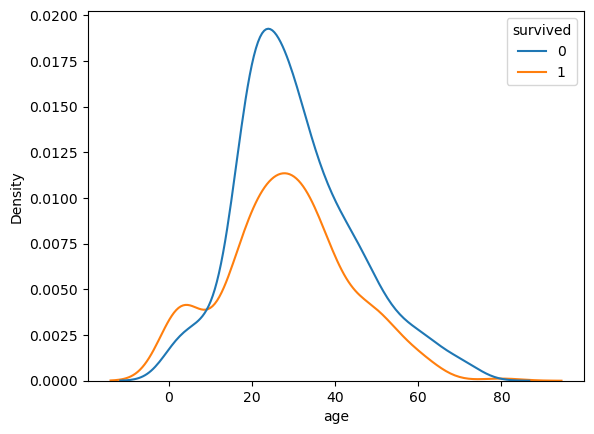

In [64]:
#Method to do above question
# sns.histplot(data=df,x='age',hue='survived',kde=True)
sns.kdeplot(data=df,x='age',hue='survived')

<Axes: xlabel='survived', ylabel='fare'>

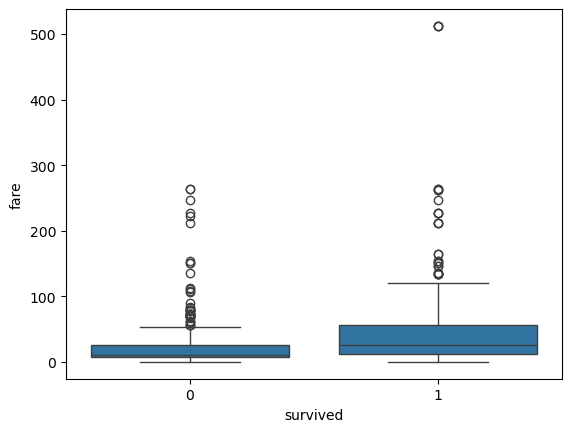

In [69]:
#14. How does fare relate to survival?
sns.boxplot(x='survived', y='fare', data=df)
# sns.kdeplot(data=df, x='fare', hue='survived', fill=True, common_norm=False)

<Axes: xlabel='embark_town', ylabel='count'>

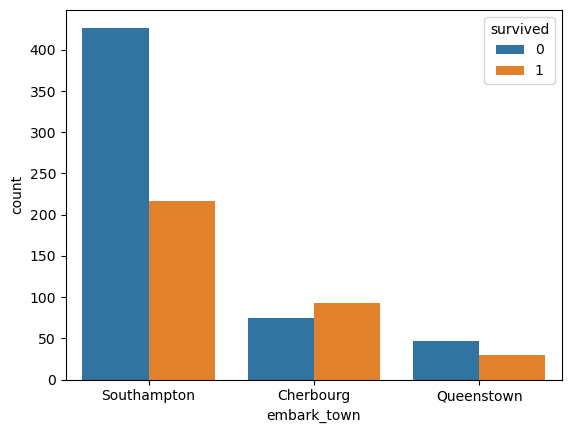

In [66]:
#15. Does embarking port influence survival rate?
sns.countplot(data=df,x='embark_town',hue='survived')

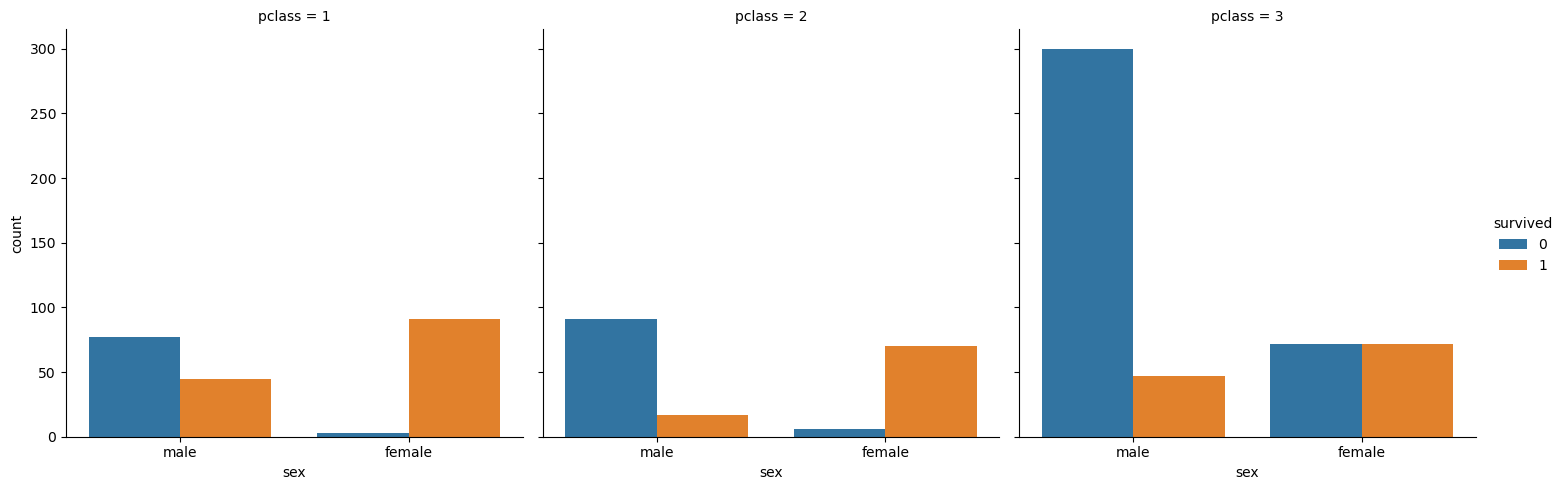

In [72]:
#16. How does survival vary across gender and passenger class together?
sns.catplot(x="sex",col="pclass",data=df,kind="count",hue="survived")   

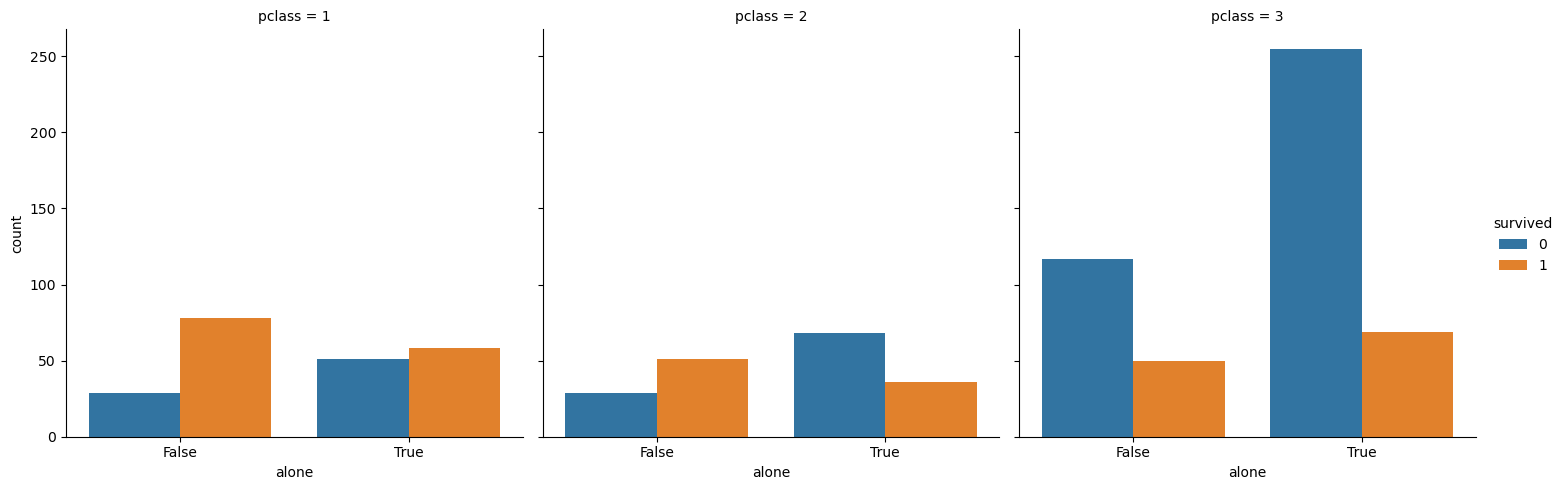

In [74]:
#17. What is the survival pattern for families vs solo travelers across classes?
sns.catplot(x="alone",col="pclass",hue="survived",kind="count",data=df)

<Axes: xlabel='age', ylabel='fare'>

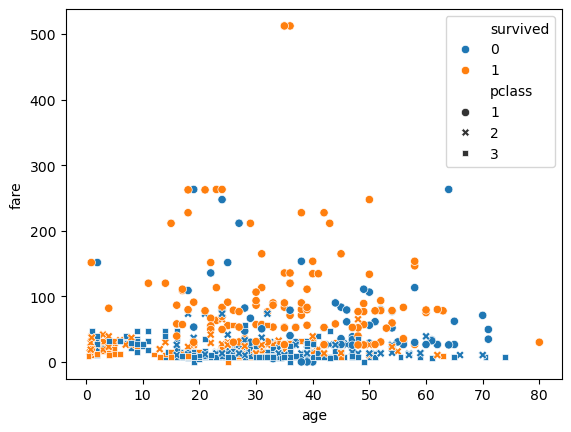

In [76]:
#18. How does age, fare, and class together influence survival?
sns.scatterplot(x='age',y='fare',hue='survived',style='pclass',data=df)

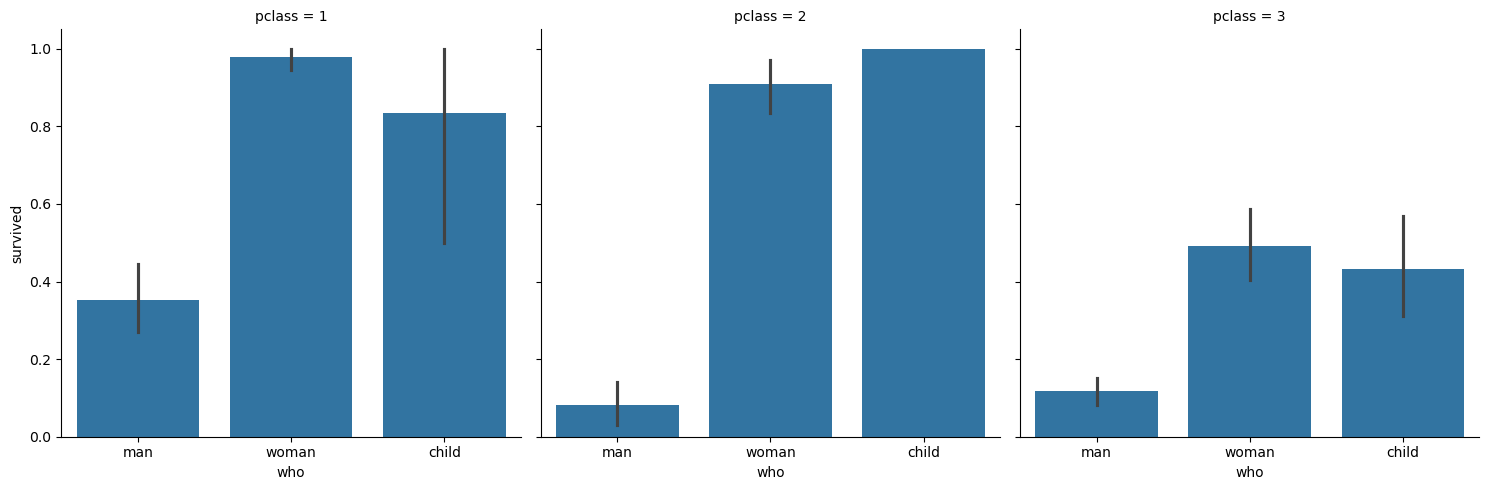

In [86]:
#19. Are women and children given priority across all classes?
sns.catplot(x='who', y='survived', col='pclass', kind='bar', data=df)
plt.show()


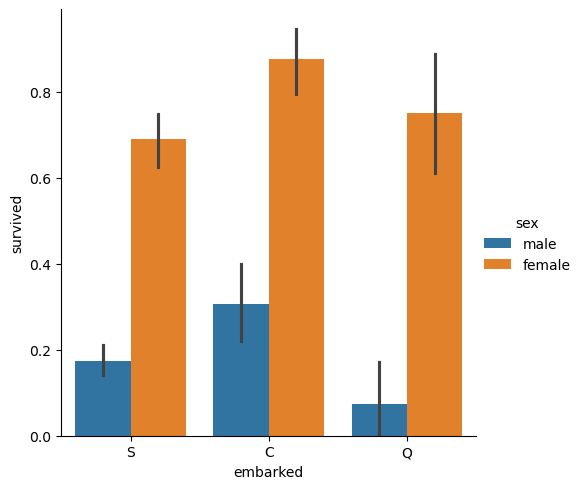

In [93]:
#20. How does survival differ for males and females across embarkation ports?
sns.catplot(x="embarked", y="survived", hue="sex", kind="bar", data=df)